# Análisis exploratorio de datos de viviendas

## Diseño y evaluación de modelos basados en aprendizaje automático

Este notebook acompaña a la **Unidad 1** y utiliza el archivo `viviendas.csv`.

Objetivos:

- Explorar un conjunto de datos.
- Identificar variables de entrada y variable objetivo.
- Analizar tipos y distribuciones.
- Estudiar correlaciones lineales.
- Comparar Pearson y Spearman.
- Detectar posibles relaciones no lineales.
- Codificar variables categóricas.
- Aplicar transformaciones y escalado.
- Realizar una selección inicial de variables.
- Documentar las decisiones.

> **Nota:** los datos son sintéticos y tienen finalidad exclusivamente didáctica.


## 1. Importar las librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_regression

plt.rcParams["figure.figsize"] = (8, 5)


## 2. Cargar el conjunto de datos

Coloca `viviendas.csv` en la misma carpeta que este notebook.


In [3]:
df = pd.read_csv("viviendas.csv")

df.head()


,id_vivienda,superficie,habitaciones,antiguedad,municipio,ascensor,planta,precio
0,1001,156,3,10,Granada,Sí,4,395000
1,1002,97,2,22,Málaga,Sí,2,302000
2,1003,72,1,22,Granada,Sí,3,205000
3,1004,111,3,30,Córdoba,Sí,4,329000
4,1005,112,2,40,Sevilla,Sí,6,200000


## 3. Conocer la estructura del dataset

In [3]:
print("Filas y columnas:", df.shape)
print("\nInformación:")
df.info()


Filas y columnas: (120, 8)

Información:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id_vivienda   120 non-null    int64 
 1   superficie    120 non-null    int64 
 2   habitaciones  120 non-null    int64 
 3   antiguedad    120 non-null    int64 
 4   municipio     120 non-null    object
 5   ascensor      120 non-null    object
 6   planta        120 non-null    int64 
 7   precio        120 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 7.6+ KB


### Estadísticas descriptivas

In [4]:
df.describe(include="all")


,id_vivienda,superficie,habitaciones,antiguedad,municipio,ascensor,planta,precio
count,120.000000,120.000000,120.000000,120.000000,120,120,120.000000,120.000000
unique,NaN,NaN,NaN,NaN,5,2,NaN,NaN
top,NaN,NaN,NaN,NaN,Málaga,Sí,NaN,NaN
freq,NaN,NaN,NaN,NaN,32,101,NaN,NaN
mean,1060.500000,105.700000,2.816667,23.825000,NaN,NaN,3.200000,300875.000000
std,34.785054,33.410259,1.076747,14.901166,NaN,NaN,2.124685,83856.576487
min,1001.000000,45.000000,1.000000,0.000000,NaN,NaN,0.000000,154000.000000
25%,1030.750000,81.250000,2.000000,12.750000,NaN,NaN,2.000000,242500.000000
50%,1060.500000,100.500000,3.000000,24.000000,NaN,NaN,3.000000,281000.000000
75%,1090.250000,125.250000,3.000000,33.250000,NaN,NaN,5.000000,354250.000000


## 4. Identificar las variables

En este problema:

- **Variable objetivo (`y`)**: `precio`
- **Variables de entrada (`X`)**: las características disponibles antes de conocer el precio.
- `id_vivienda` es un identificador y no una característica predictiva.


In [4]:
df.columns


Index(['id_vivienda', 'superficie', 'habitaciones', 'antiguedad', 'municipio',
       'ascensor', 'planta', 'precio'],
      dtype='object')

## 5. Variables categóricas y numéricas

In [6]:
print("Variables numéricas:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nVariables categóricas:")
print(df.select_dtypes(exclude="number").columns.tolist())


Variables numéricas:
['id_vivienda', 'superficie', 'habitaciones', 'antiguedad', 'planta', 'precio']

Variables categóricas:
['municipio', 'ascensor']


## 6. Valores ausentes

In [7]:
df.isna().sum()


,0
id_vivienda,0
superficie,0
habitaciones,0
antiguedad,0
municipio,0
ascensor,0
planta,0
precio,0


## 7. Distribución de variables numéricas

Comenzamos observando la distribución del precio.


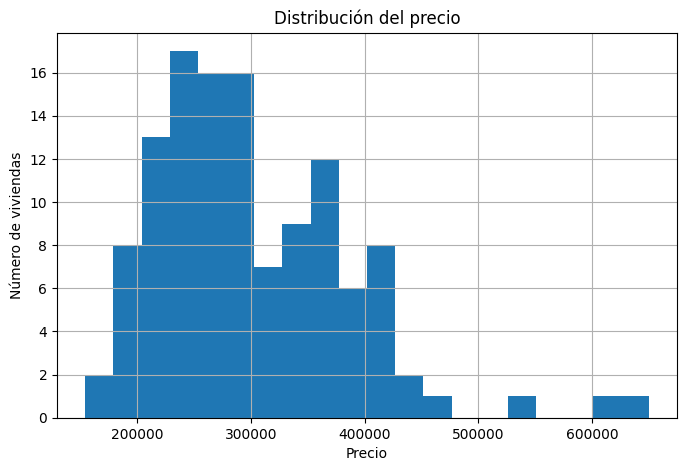

In [8]:
df["precio"].hist(bins=20)
plt.xlabel("Precio")
plt.ylabel("Número de viviendas")
plt.title("Distribución del precio")
plt.show()


Otra forma de visualizar la distribución de una variable es a través de un boxplot

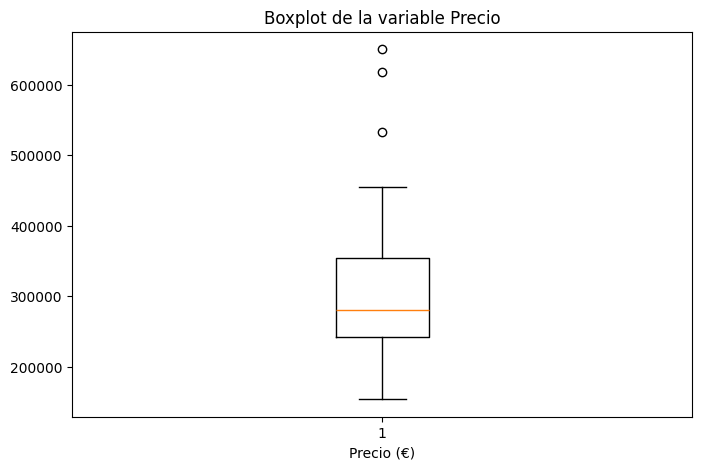

Outliers: 3


In [ ]:
plt.boxplot(df["precio"], vert=True)
plt.xlabel("Precio (€)")
plt.title("Boxplot de la variable Precio")
plt.show()

q1, q3 = df["precio"].quantile([0.25, 0.75])
iqr = q3 - q1
n_outliers = ((df["precio"] < q1 - 1.5 * iqr) | (df["precio"] > q3 + 1.5 * iqr)).sum()
print(f"Outliers: {n_outliers}")

Vemos la distribución del resto de las variables. Para que una variable tenga una buena distribución debe seguir una distribución de campana de Gauss.

Junto al histograma se presenta su ajuste a la campana, de forma que podamos observar si hay algún sesgo.

A las variables categóricas no posible dibujarles la distribución gaussiana.

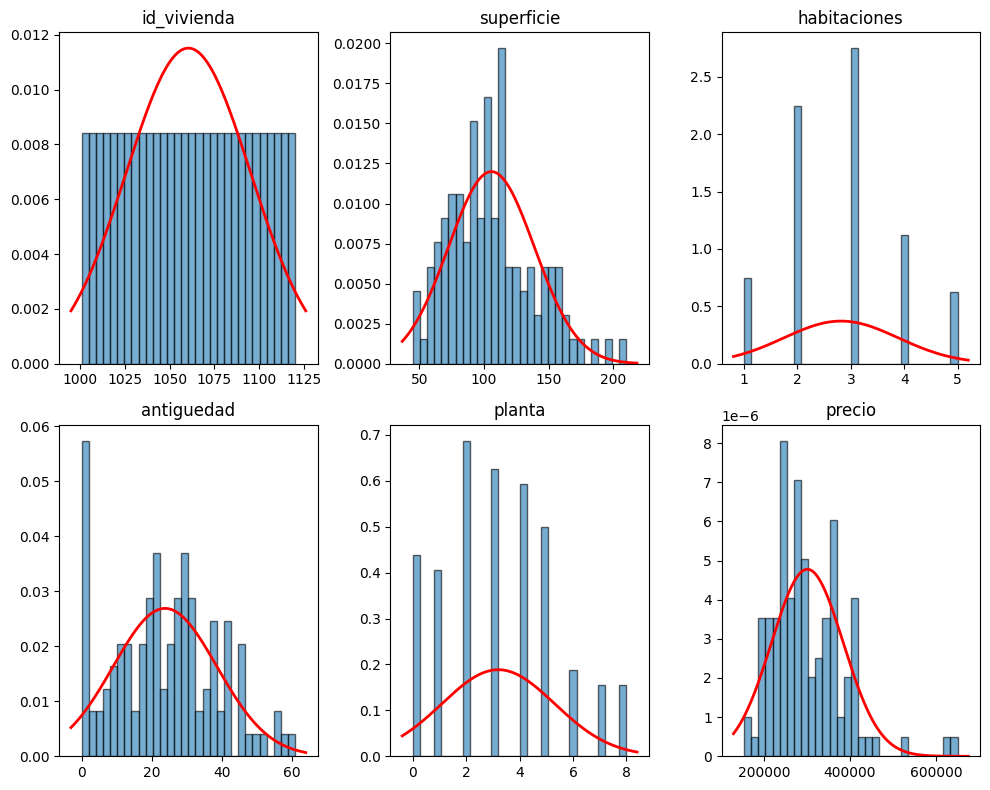

In [10]:
from scipy.stats import norm, skewnorm

# Figura 2×2
fig, axes = plt.subplots(2, 3, figsize=(10, 8))
for ax, col in zip(axes.flatten(), df.drop(['municipio','ascensor'],axis=1)):
    ax.hist(df[col], bins=30, density=True, alpha=0.6, edgecolor="black")
    if col != "OrdinalUniform":               # curva solo para variables continuas
        mu, std = norm.fit(df[col])
        x = np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 200)
        ax.plot(x, norm.pdf(x, mu, std), "r", linewidth=2)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Para las variables categóricas vamos a mostrar diagramas de sectores, para comprobar si las clases están bien balanceadas.

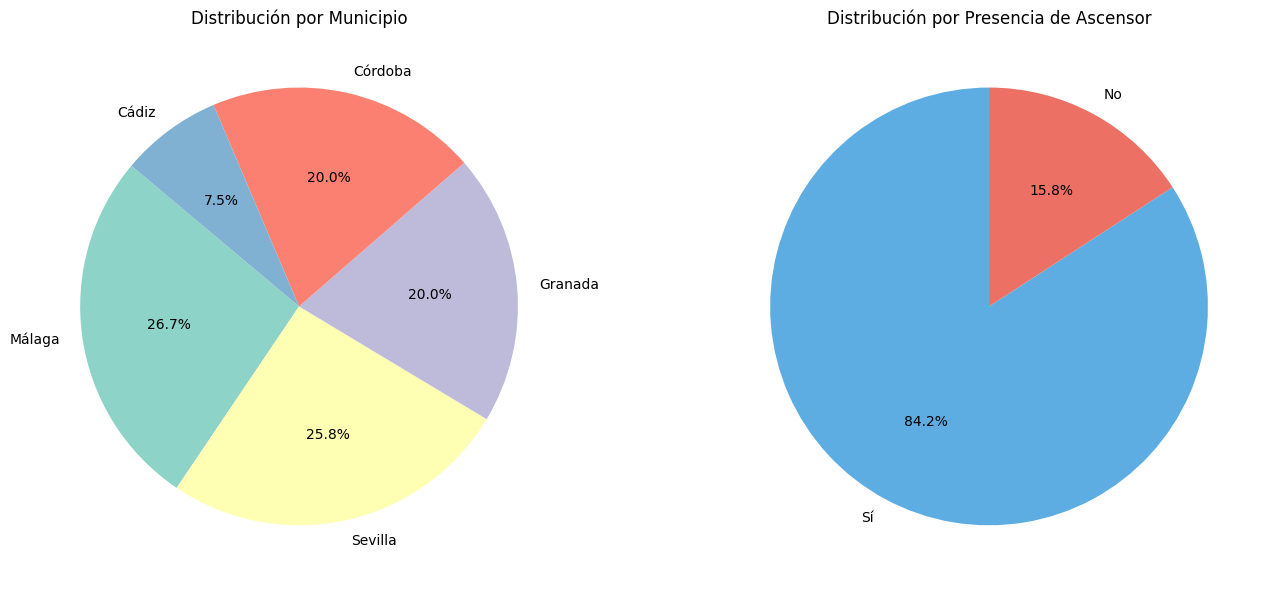

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Diagrama de sectores para Municipio
municipio_counts = df['municipio'].value_counts()
axes[0].pie(municipio_counts, labels=municipio_counts.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.Set3.colors)
axes[0].set_title('Distribución por Municipio')

# Diagrama de sectores para Ascensor
ascensor_counts = df['ascensor'].value_counts()
axes[1].pie(ascensor_counts, labels=ascensor_counts.index, autopct='%1.1f%%', startangle=90, colors=['#5dade2', '#ec7063'])
axes[1].set_title('Distribución por Presencia de Ascensor')

plt.tight_layout()
plt.show()

## 8. Relación entre superficie y precio

Utilizamos un gráfico de dispersión para comprobar visualmente la relación.


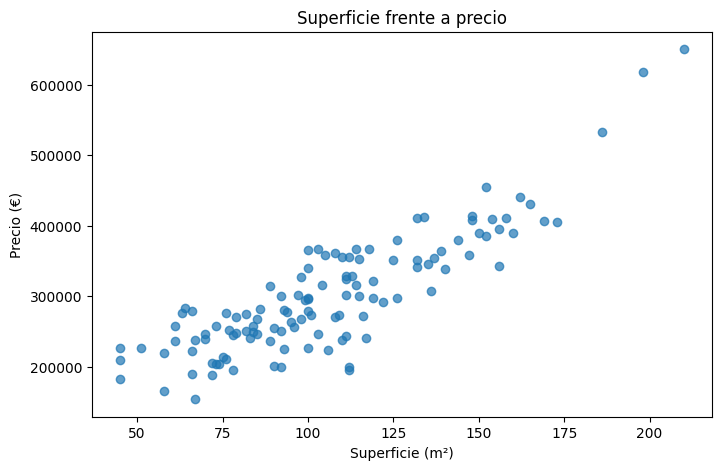

In [12]:
plt.scatter(df["superficie"], df["precio"], alpha=0.7)
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio (€)")
plt.title("Superficie frente a precio")
plt.show()


## 9. Correlación de Pearson

Calculamos las correlaciones entre las variables numéricas.


In [13]:
corr = df.corr(numeric_only=True)

corr["precio"].sort_values(ascending=False)


,precio
precio,1.000000
superficie,0.858637
habitaciones,0.690684
planta,0.079898
id_vivienda,-0.036611
antiguedad,-0.099273


### Interpretación

Observa especialmente:

- `superficie`
- `habitaciones`
- `antiguedad`
- `planta`

La correlación nos proporciona una **primera pista**, pero no constituye por sí sola una decisión definitiva.


## 10. Comparar Pearson y Spearman

Spearman resulta útil para estudiar relaciones monótonas que no tienen que ser estrictamente lineales.


In [14]:
pearson = df.corr(numeric_only=True, method="pearson")["precio"]
spearman = df.corr(numeric_only=True, method="spearman")["precio"]

comparacion = pd.DataFrame({
    "Pearson": pearson,
    "Spearman": spearman
})

comparacion.sort_values("Pearson", ascending=False)


,Pearson,Spearman
precio,1.000000,1.000000
superficie,0.858637,0.804667
habitaciones,0.690684,0.679481
planta,0.079898,0.129862
id_vivienda,-0.036611,0.005483
antiguedad,-0.099273,-0.167398


## 11. Analizar posibles relaciones no lineales

La correlación de Pearson puede ser baja cuando existe una relación no lineal.

Vamos a visualizar algunas variables frente al precio.


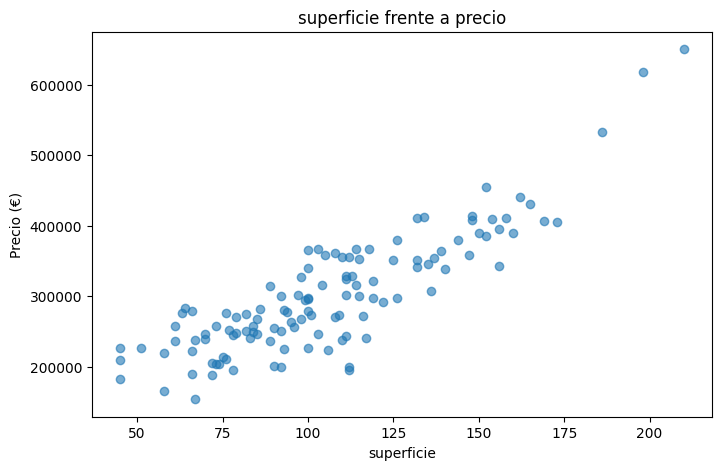

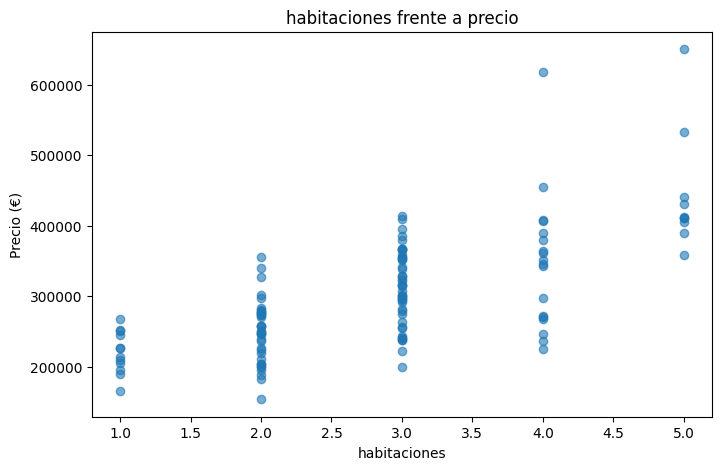

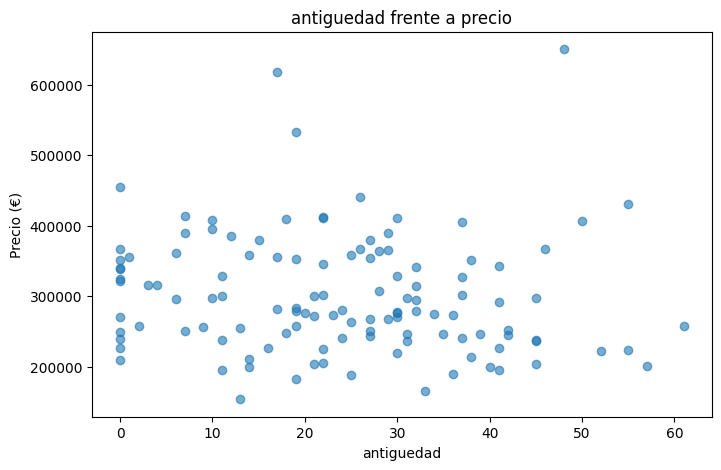

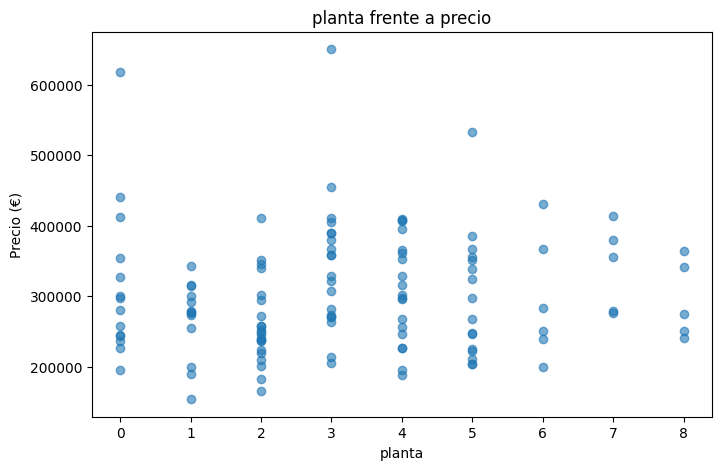

In [15]:
variables = ["superficie", "habitaciones", "antiguedad", "planta"]

for variable in variables:
    plt.scatter(df[variable], df["precio"], alpha=0.6)
    plt.xlabel(variable)
    plt.ylabel("Precio (€)")
    plt.title(f"{variable} frente a precio")
    plt.show()


## 12. Correlaciones entre variables de entrada

No solo debemos estudiar la relación con `precio`.

También interesa detectar variables de entrada muy relacionadas entre sí.


In [16]:
variables_numericas = [
    "superficie",
    "habitaciones",
    "antiguedad",
    "planta",
    "precio"
]

df[variables_numericas].corr()


,superficie,habitaciones,antiguedad,planta,precio
superficie,1.000000,0.765577,0.001193,0.031631,0.858637
habitaciones,0.765577,1.000000,-0.004635,0.041875,0.690684
antiguedad,0.001193,-0.004635,1.000000,-0.032859,-0.099273
planta,0.031631,0.041875,-0.032859,1.000000,0.079898
precio,0.858637,0.690684,-0.099273,0.079898,1.000000


Una forma visual de representar la correlación entre las variables es a través de un mapa de calor.

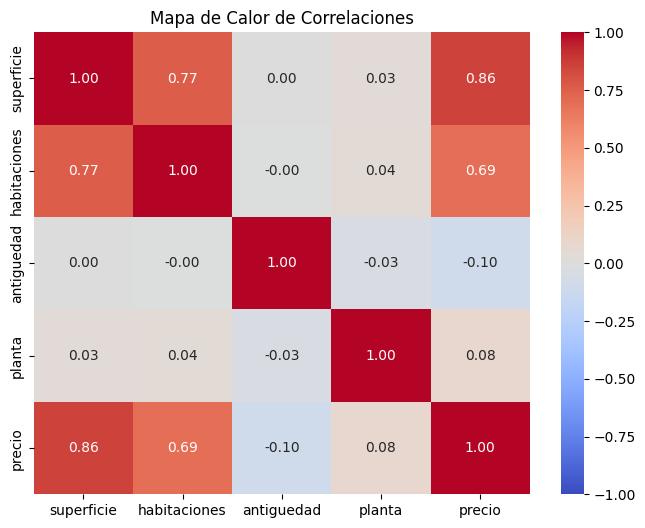

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculamos la matriz de correlación para las variables numéricas de interés
variables_numericas = ['superficie', 'habitaciones', 'antiguedad', 'planta', 'precio']
matriz_corr = df[variables_numericas].corr()

# Dibujamos el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones')
plt.show()

## 13. Codificación de variables categóricas

`municipio` es una variable categórica nominal.

No queremos convertir:

- Sevilla → 1
- Málaga → 2
- Córdoba → 3

porque esos números podrían sugerir un orden inexistente.

Utilizaremos One-Hot Encoding.


In [18]:
df["municipio"].value_counts()


,count
municipio,
Málaga,32
Sevilla,31
Granada,24
Córdoba,24
Cádiz,9


### One-Hot Encoding con pandas

In [19]:
df_encoded = pd.get_dummies(
    df,
    columns=["municipio"],
    dtype=int
)

df_encoded.head()


,id_vivienda,superficie,habitaciones,antiguedad,ascensor,planta,precio,municipio_Cádiz,municipio_Córdoba,municipio_Granada,municipio_Málaga,municipio_Sevilla
0,1001,156,3,10,Sí,4,395000,0,0,1,0,0
1,1002,97,2,22,Sí,2,302000,0,0,0,1,0
2,1003,72,1,22,Sí,3,205000,0,0,1,0,0
3,1004,111,3,30,Sí,4,329000,0,1,0,0,0
4,1005,112,2,40,Sí,6,200000,0,0,0,0,1


## 14. Variables binarias

`ascensor` tiene dos categorías.

Podemos convertirla a 0/1.


In [20]:
df["ascensor_binario"] = df["ascensor"].map({
    "No": 0,
    "Sí": 1
})

df[["ascensor", "ascensor_binario"]].head()


,ascensor,ascensor_binario
0,Sí,1
1,Sí,1
2,Sí,1
3,Sí,1
4,Sí,1


## 15. Distribución sesgada y transformación logarítmica

Cuando una variable presenta una distribución muy asimétrica puede ser interesante estudiar una transformación logarítmica.

Aquí creamos una versión transformada del precio:


In [21]:
df["precio_log"] = np.log1p(df["precio"])

df[["precio", "precio_log"]].head()


,precio,precio_log
0,395000,12.886644
1,302000,12.618186
2,205000,12.230770
3,329000,12.703816
4,200000,12.206078


## 16. Estandarización

La estandarización transforma una variable para que tenga aproximadamente:

- media = 0
- desviación típica = 1

Es especialmente útil para algoritmos sensibles a la escala.


In [ ]:
variables_escalado = [
    "superficie",
    "habitaciones",
    "antiguedad",
    "planta"
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df[variables_escalado]
)

df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_escalado
)

df_scaled.head()


,superficie,habitaciones,antiguedad,planta
0,1.511838,0.170980,-0.931670,0.378105
1,-0.261491,-0.761638,-0.122987,-0.567158
2,-1.012901,-1.694255,-0.122987,-0.094526
3,0.159299,0.170980,0.416135,0.378105
4,0.189355,-0.761638,1.090037,1.323368


## 17. Normalización Min-Max

Otra alternativa es transformar las variables al intervalo [0, 1].


In [ ]:
minmax = MinMaxScaler()

X_minmax = minmax.fit_transform(
    df[variables_escalado]
)

df_minmax = pd.DataFrame(
    X_minmax,
    columns=variables_escalado
)

df_minmax.head()


,superficie,habitaciones,antiguedad,planta
0,0.672727,0.50,0.163934,0.500
1,0.315152,0.25,0.360656,0.250
2,0.163636,0.00,0.360656,0.375
3,0.400000,0.50,0.491803,0.500
4,0.406061,0.25,0.655738,0.750


## 18. Información mutua

La información mutua puede detectar dependencias que no tienen por qué ser lineales.

En este ejemplo la utilizaremos como herramienta complementaria.


In [24]:
X = df[
    ["superficie", "habitaciones", "antiguedad", "planta"]
]

y = df["precio"]

mi = mutual_info_regression(
    X,
    y,
    random_state=42
)

pd.Series(
    mi,
    index=X.columns
).sort_values(ascending=False)


,0
superficie,0.622935
habitaciones,0.347299
planta,0.038004
antiguedad,0.002805


## 19. Una primera selección de variables

A partir del análisis podemos construir una selección inicial.

Ejemplo de razonamiento:

- `superficie`: candidata clara.
- `habitaciones`: potencialmente útil, pero relacionada con superficie.
- `antiguedad`: puede aportar información.
- `planta`: estudiar su aportación real.
- `municipio`: mantener y codificar.
- `ascensor`: mantener como variable binaria.
- `id_vivienda`: descartar porque es un identificador.

**Importante:** estas decisiones son hipótesis iniciales que deberían validarse posteriormente con modelos y técnicas de selección de características.


## 20. Crear X e y

Separamos las variables de entrada de la variable objetivo.


In [25]:
X = df.drop(
    columns=["precio", "precio_log", "id_vivienda"]
)

y = df["precio"]

X.head(), y.head()


(   superficie  habitaciones  antiguedad municipio ascensor  planta  \
 0         156             3          10   Granada       Sí       4   
 1          97             2          22    Málaga       Sí       2   
 2          72             1          22   Granada       Sí       3   
 3         111             3          30   Córdoba       Sí       4   
 4         112             2          40   Sevilla       Sí       6   
 
    ascensor_binario  
 0                 1  
 1                 1  
 2                 1  
 3                 1  
 4                 1  ,
 0    395000
 1    302000
 2    205000
 3    329000
 4    200000
 Name: precio, dtype: int64)

## 21. Informe automático inicial

Podemos generar una tabla que nos ayude a documentar el análisis.


In [26]:
informe = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_unicos": df.nunique()
})

informe


,tipo,nulos,valores_unicos
id_vivienda,int64,0,120
superficie,int64,0,76
habitaciones,int64,0,5
antiguedad,int64,0,49
municipio,object,0,5
ascensor,object,0,2
planta,int64,0,9
precio,int64,0,99
ascensor_binario,int64,0,2
precio_log,float64,0,99


## 22. Actividad para el alumnado

A partir de este notebook:

1. Analiza todas las variables.
2. Calcula Pearson y Spearman.
3. Busca diferencias importantes entre ambos coeficientes.
4. Identifica posibles relaciones no lineales.
5. Analiza las variables categóricas.
6. Aplica One-Hot Encoding.
7. Prueba una transformación logarítmica sobre otra variable.
8. Compara StandardScaler y MinMaxScaler.
9. Calcula información mutua.
10. Propón un conjunto final de variables de entrada.
11. Justifica las variables descartadas.
12. Redacta un pequeño informe técnico.

### Pregunta final

> ¿Qué variables utilizarías para construir un primer modelo de predicción del precio y por qué?


# Conclusión

El análisis exploratorio previo al entrenamiento nos permite:

- comprender los datos;
- detectar relaciones;
- encontrar redundancias;
- identificar problemas;
- transformar las variables;
- y tomar decisiones fundamentadas.

**La fase de análisis no termina al calcular una correlación: debemos interpretar los datos y relacionar los resultados con el problema que queremos resolver.**
